# Day 41 — The Widest Street

## Support Vector Machines

**Boston University · Data Science Program**

---

The slides carry the ideas. This notebook is here so you can **poke at them** — change a
number, re-run a cell, and watch the picture move.

Everything today comes from one sentence:

> **Of all the lines that separate the two groups, an SVM keeps the one with the widest
> empty street either side of it.**

| | |
|---|---|
| 1 | See the margin, and find the points that hold it open |
| 2 | Turn the `C` knob and watch the street widen and narrow |
| 3 | Watch a kernel solve a problem no straight line can |
| 4 | Turn `gamma` and see smooth become wiggly |
| 5 | Prove to yourself why an SVM must always be scaled |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter("ignore")

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

CV = StratifiedKFold(5, shuffle=True, random_state=0)
plt.rcParams["figure.figsize"] = (6.4, 5)

TEAL, CORAL, INK, AMBER = "#1F9E86", "#E05C45", "#131F33", "#F0A530"

def show(X, y, model=None, title="", ax=None, support=True):
    """Draw the points, and if a model is given, its street."""
    ax = ax or plt.gca()
    if model is not None:
        pad = 0.6
        gx, gy = np.meshgrid(
            np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 320),
            np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 320))
        Z = model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
        ax.contourf(gx, gy, Z, levels=[-1, 1], colors=["#FFF1D6"])          # the street
        ax.contour(gx, gy, Z, levels=[-1, 0, 1], colors=["#7B8AA1", INK, "#7B8AA1"],
                   linestyles=["--", "-", "--"], linewidths=[1.3, 2.4, 1.3])
        if support and hasattr(model, "support_vectors_"):
            ax.scatter(*model.support_vectors_.T, s=230, facecolors="none",
                       edgecolors="#A86F00", linewidths=2.4, zorder=6)
    for cls, col, mk in [(0, TEAL, "o"), (1, CORAL, "s")]:
        m = y == cls
        ax.scatter(X[m, 0], X[m, 1], c=col, marker=mk, s=70, zorder=5,
                   edgecolors="white", linewidths=1.4)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=12)

print("ready")

ready


---
# 1 · The street, and the points that hold it open

Two clean groups. Nothing fancy.

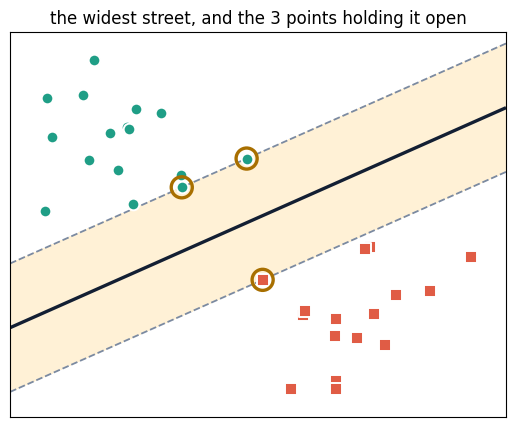

training points : 32
support vectors : 3 -> [8, 14, 28]
that is 9% of the data


In [31]:
rng = np.random.default_rng(41)
A = rng.normal([2.4, 6.2], [1.05, 1.0], (16, 2))
B = rng.normal([6.6, 2.6], [1.05, 1.0], (16, 2))
X = np.vstack([A, B])
y = np.r_[np.zeros(16), np.ones(16)]

svm = SVC(kernel="linear", C=0.9).fit(X, y)      # huge C = "allow no mistakes"
show(X, y, svm, "the widest street, and the 3 points holding it open")
plt.show()

print("training points :", len(X))
print("support vectors :", len(svm.support_), "->", sorted(svm.support_.tolist()))
print("that is", f"{len(svm.support_) / len(X) * 100:.0f}% of the data")

The shaded band is the **street** (the margin), the solid line runs down its middle, and
the three circled points are the **support vectors** — the only points touching a kerb.

## 1.1 · Prove that the other 29 points do not matter

If the claim on the slides is true, we can throw away every point that is not a support
vector, refit, and get the same boundary back.

In [3]:
keep_X = X[svm.support_]
keep_y = y[svm.support_]
svm_3 = SVC(kernel="linear", C=1e6).fit(keep_X, keep_y)

def line_of(m):                    # direction + offset, ignoring overall scale
    n = np.linalg.norm(m.coef_[0])
    return (m.coef_[0] / n).round(3), round(m.intercept_[0] / n, 3)

print("all 32 points :", *line_of(svm))
print("only 3 points :", *line_of(svm_3))
print()
print("same prediction on all 32 original rows:",
      (svm.predict(X) == svm_3.predict(X)).all())

all 32 points : [ 0.482 -0.876] 1.909
only 3 points : [ 0.481 -0.877] 1.913

same prediction on all 32 original rows: True


Same direction, same offset, same predictions. **29 of the 32 rows were irrelevant.**

(The two fits agree to three decimals rather than bit-for-bit — that is just the solver
stopping in a slightly different place, not a different boundary.)

That is the single most distinctive thing about an SVM. A forest looks at every row; an
SVM is defined entirely by the handful of rows closest to the enemy.

> Try it yourself: move one of the *far* points in the cell above (change a number in
> `A` or `B`) and re-run. The boundary will not budge — unless you happen to push that
> point onto the kerb.

---
# 2 · C — the price of a mistake

Clean data was the easy case. Now let the groups overlap, so **no** line can separate
them perfectly.

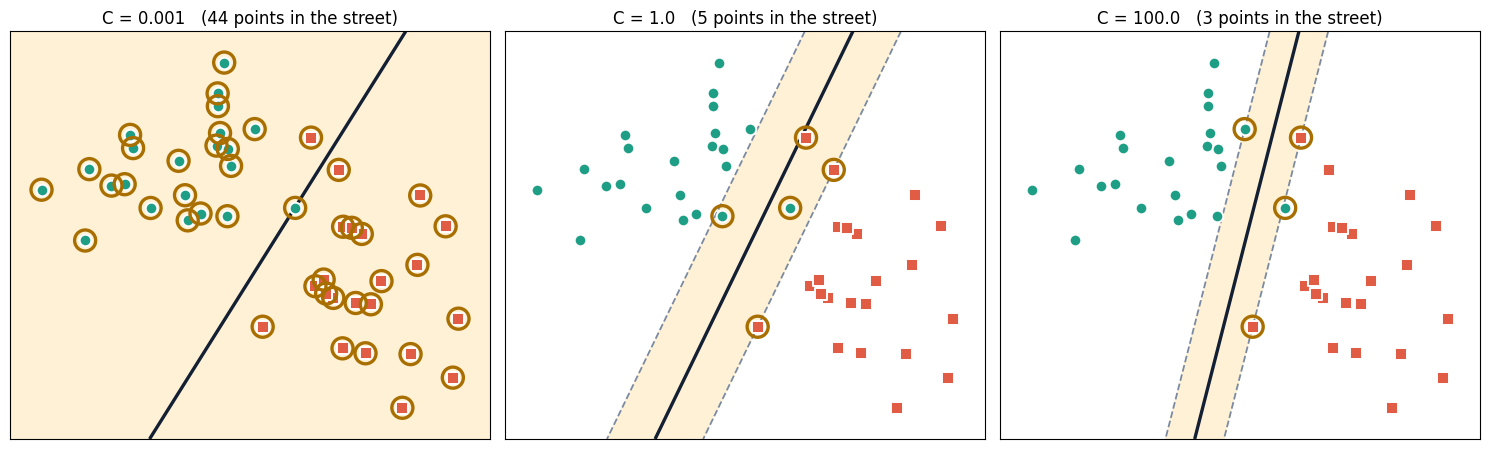

In [33]:
r2 = np.random.default_rng(7)
Xo = np.vstack([r2.normal([3.3, 5.6], [1.35, 1.3], (22, 2)),
                r2.normal([5.9, 3.3], [1.35, 1.3], (22, 2))])
yo = np.r_[np.zeros(22), np.ones(22)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, c in zip(axes, [0.001, 1.0, 100.0]):
    m = SVC(kernel="linear", C=c).fit(Xo, yo)
    inside = (np.abs(m.decision_function(Xo)) < 1).sum()
    show(Xo, yo, m, f"C = {c}   ({inside} points in the street)", ax=ax)
plt.tight_layout(); plt.show()

`C` is the **price charged for every point allowed to stand inside the street**.

- **Small C** — mistakes are cheap, so the model buys a very wide street and lets plenty
  of points stand in it. Simple, smooth, and it may be *too* relaxed (underfitting).
- **Large C** — mistakes are expensive, so the street is squeezed until almost nobody is
  inside. The boundary contorts itself around awkward points (overfitting).

Neither end is right. You find the value in between the same way you found `max_depth`
on Day 39 and `n_estimators` on Day 40 — by searching.

In [5]:
for c in [0.01, 0.1, 1, 10, 100]:
    s = cross_val_score(SVC(kernel="linear", C=c), Xo, yo, cv=CV).mean()
    print(f"  C = {c:>6}   cross-validated accuracy {s:.4f}")

  C =   0.01   cross-validated accuracy 0.9528
  C =    0.1   cross-validated accuracy 0.9528
  C =      1   cross-validated accuracy 0.9750
  C =     10   cross-validated accuracy 0.9306
  C =    100   cross-validated accuracy 0.9306


---
# 3 · When no straight line can work

Here is the problem from the slides: one group in the middle, the other in a ring
around it.

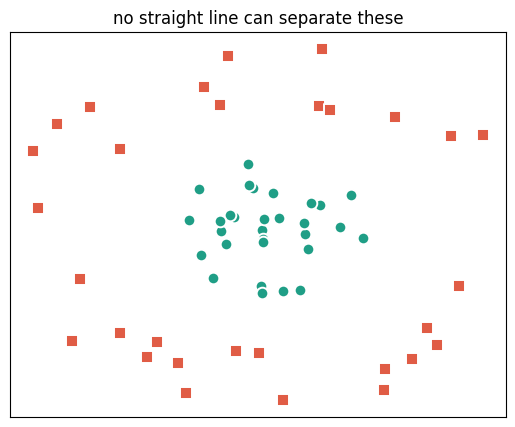

  always guess the bigger group  0.5
  straight-line SVM              0.6
  logistic regression            0.4167


In [6]:
ang = np.random.default_rng(3).uniform(0, 2 * np.pi, 60)
rad = np.r_[np.random.default_rng(4).uniform(0.0, 1.15, 30),
            np.random.default_rng(5).uniform(2.1, 3.1, 30)]
Xr = np.c_[rad * np.cos(ang), rad * np.sin(ang)]
yr = np.r_[np.zeros(30), np.ones(30)]

show(Xr, yr, title="no straight line can separate these")
plt.show()

print("  always guess the bigger group ", round(max(yr.mean(), 1 - yr.mean()), 4))
print("  straight-line SVM             ",
      round(cross_val_score(SVC(kernel="linear"), Xr, yr, cv=CV).mean(), 4))
print("  logistic regression           ",
      round(cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                            Xr, yr, cv=CV).mean(), 4))

Every straight-line method is at or below a coin flip. Logistic regression actually
scores **worse than guessing**, because the best line it can find is actively
misleading.

## 3.1 · The trick: look at the data from somewhere else

Add a third coordinate — how far each point sits from the centre. The ring rises, the
middle group stays low, and a flat sheet slides between them.

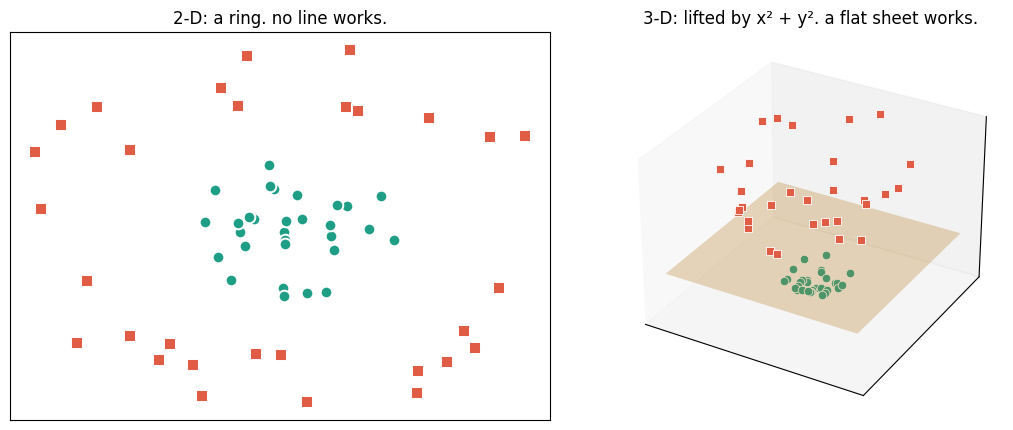

In [7]:
z = Xr[:, 0] ** 2 + Xr[:, 1] ** 2        # the extra dimension

fig = plt.figure(figsize=(11, 4.4))
ax1 = fig.add_subplot(121)
show(Xr, yr, title="2-D: a ring. no line works.", ax=ax1)

ax2 = fig.add_subplot(122, projection="3d")
for cls, col, mk in [(0, TEAL, "o"), (1, CORAL, "s")]:
    m = yr == cls
    ax2.scatter(Xr[m, 0], Xr[m, 1], z[m], c=col, marker=mk, s=38,
                edgecolors="white", linewidths=0.6, depthshade=False)
g = np.linspace(-3.4, 3.4, 2); GX, GY = np.meshgrid(g, g)
ax2.plot_surface(GX, GY, np.full_like(GX, 2.6), color=AMBER, alpha=0.3)
ax2.set_title("3-D: lifted by x\u00b2 + y\u00b2. a flat sheet works.", fontsize=12)
ax2.set_xticks([]); ax2.set_yticks([]); ax2.set_zticks([])
plt.tight_layout(); plt.show()

## 3.2 · A kernel does this without building the extra column

Writing `kernel="rbf"` gets you the benefit of those extra dimensions without ever
creating them. That is the whole "kernel trick" — the expensive step turns out to be
unnecessary.

  straight-line SVM   0.6
  rbf SVM             1.0


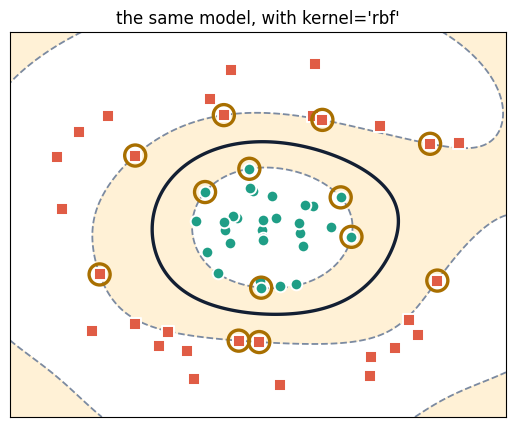

In [37]:
print("  straight-line SVM  ",
      round(cross_val_score(SVC(kernel="linear"), Xr, yr, cv=CV).mean(), 4))
print("  rbf SVM            ",
      round(cross_val_score(SVC(kernel="rbf", C=10, gamma=0.393), Xr, yr, cv=CV).mean(), 4))

show(Xr, yr, SVC(kernel="rbf", C=10, gamma=0.393).fit(Xr, yr),
     "the same model, with kernel='rbf'")
plt.show()

From 0.6000 to a perfect 1.0000, by changing one word.

Notice what did **not** change: it is still an SVM looking for the widest street. The
street is just being measured in a space we never had to build.

---
# 4 · gamma — how local the curve is allowed to be

The rbf kernel brings a second knob. `gamma` controls how far one point's influence
reaches.

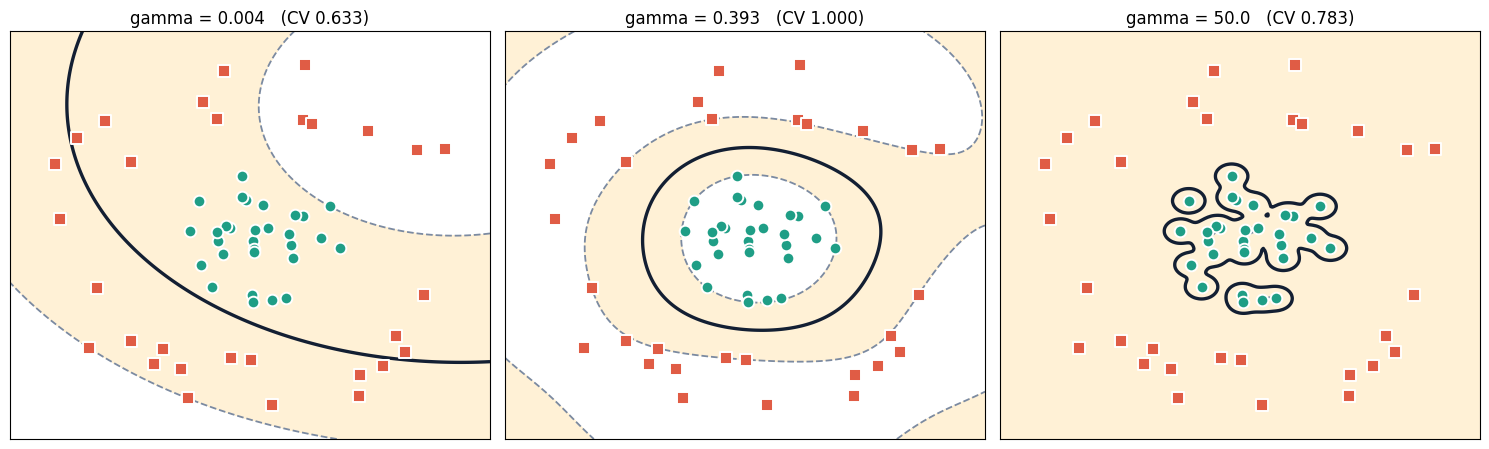

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, g in zip(axes, [0.004, 0.393, 50.0]):
    m = SVC(kernel="rbf", C=10, gamma=g).fit(Xr, yr)
    acc = cross_val_score(SVC(kernel="rbf", C=10, gamma=g), Xr, yr, cv=CV).mean()
    show(Xr, yr, m, f"gamma = {g}   (CV {acc:.3f})", ax=ax, support=False)
plt.tight_layout(); plt.show()

| gamma | what it draws | what happens |
|---|---|---|
| too small | one huge smooth region | cannot bend around the ring — **underfits** |
| about right | a clean circle | finds the real shape |
| too large | an island around each point | has memorised the data — **overfits** |

`C` and `gamma` fail in the same direction, which is exactly why you search them
**together** rather than one at a time.

In [10]:
grid = GridSearchCV(SVC(),
                    {"C": [0.1, 1, 10, 100], "gamma": [0.001, 0.01, 0.1, 1]},
                    cv=CV, n_jobs=-1).fit(Xr, yr)
print("best:", grid.best_params_, "->", round(grid.best_score_, 4))
print("models fitted:", 4 * 4, "combinations x 5 folds =", 4 * 4 * 5)

best: {'C': 1, 'gamma': 0.1} -> 1.0
models fitted: 16 combinations x 5 folds = 80


---
# 5 · Always scale first

An SVM finds the widest gap by **measuring distances**. If one column runs in hundreds
of thousands and another in tens, the big column decides everything — the same trap as
k-NN on Day 38.

In [11]:
r = np.random.default_rng(411)
N = 300
marks  = r.normal(62, 13, N).clip(0, 100)                  # tens
budget = r.normal(240000, 90000, N).clip(20000, 600000)    # hundreds of thousands
admit  = (0.055 * (marks - 62) + 0.0000075 * (budget - 240000)
          + r.normal(0, 0.35, N) > 0).astype(int)
Xa = np.c_[marks, budget]

print("  baseline (guess the bigger group)",
      round(max(admit.mean(), 1 - admit.mean()), 4))
print("  SVM, columns left as they came   ",
      round(cross_val_score(SVC(), Xa, admit, cv=CV).mean(), 4))
print("  the SAME SVM, after StandardScaler",
      round(cross_val_score(make_pipeline(StandardScaler(), SVC()), Xa, admit, cv=CV).mean(), 4))
print("  random forest, not scaled at all ",
      round(cross_val_score(RandomForestClassifier(n_estimators=200, random_state=0),
                            Xa, admit, cv=CV).mean(), 4))

  baseline (guess the bigger group) 0.52
  SVM, columns left as they came    0.75
  the SAME SVM, after StandardScaler 0.92
  random forest, not scaled at all  0.88


**Seventeen points of accuracy, from one line of code.** The forest sitting next to it
does not care at all, because a tree *compares* values rather than *measuring* distances
between them.

So the rule is simple and absolute:

```python
make_pipeline(StandardScaler(), SVC())      # never write SVC() on its own
```

---
# 6 · Summary

| | |
|---|---|
| **The idea** | Find the widest empty street between the groups; put the boundary down its middle. |
| **Support vectors** | Only the points touching a kerb matter. Here, 3 of 32. |
| **C** | The price of letting a point stand in the street. Small = wide and relaxed, large = narrow and strict. |
| **Kernels** | Change the space, not the line. A circle in 2-D is a flat cut in 3-D. `rbf` is the default. |
| **gamma** | How local the curve is. Too small underfits, too large draws islands. |
| **Scaling** | Compulsory. An SVM measures distance. |
| **Use it when** | Few rows, many columns, a clear gap, and you do not need to explain the decision. |

### Next: Day 42

We have now met the main families — linear models, neighbours, trees, forests and
margins. Next we step back and look at how to choose between them for a problem you have
never seen before.